# Spatial features

Spatial features describe multichannel audio : stereo image (pan, width, level differences), time differences and
generalized cross-correlation between microphones, covariance and cross-spectral matrices, and the Spectro-Spatial
Covariance Vector for ambisonics. All of them work on `(..., channels, samples)` inputs, per frame.

In [1]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt
from acids_dataset import features as F

SR = 16000
torch.manual_seed(0)
N = 4 * SR
t = torch.arange(N) / SR

def fractional_delay(x, delay):
    """delays x by a (fractional) number of samples, in the Fourier domain."""
    f = torch.fft.rfftfreq(x.shape[-1])
    return torch.fft.irfft(torch.fft.rfft(x) * torch.exp(-2j * math.pi * f * delay), n=x.shape[-1])

def lowpass(x, cutoff):
    f = torch.fft.rfftfreq(x.shape[-1], 1 / SR)
    return torch.fft.irfft(torch.fft.rfft(x) * (f < cutoff), n=x.shape[-1])

source = 0.3 * torch.randn(N)

## Stereo image : pan, level differences and width

A source moving from left to right with constant-power panning. `Pan` gives the position from channel energies in
[-1, 1], and `InterChannelLevelDifference` the level of each channel relative to the first one (dB).

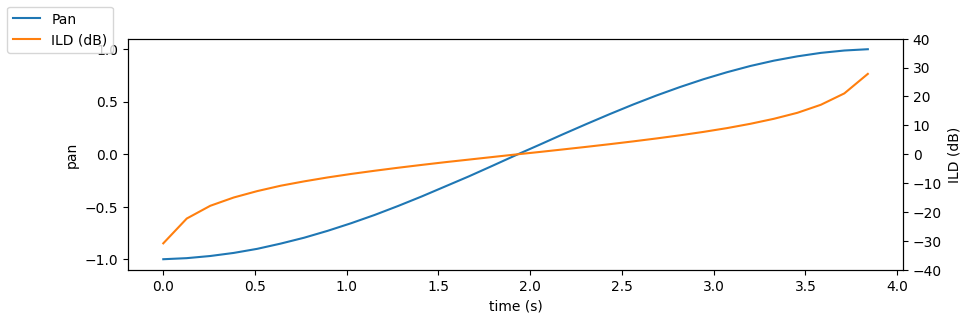

In [2]:
angle = torch.linspace(0, math.pi / 2, N)
stereo = torch.stack([torch.cos(angle) * source, torch.sin(angle) * source])
pan = F.Pan(sr=SR)(stereo)
ild = F.InterChannelLevelDifference(sr=SR)(stereo)

fig, ax1 = plt.subplots(figsize=(10, 3))
frames = torch.arange(len(pan)) * 2048 / SR
ax1.plot(frames, pan, label="Pan"); ax1.set_ylabel("pan"); ax1.set_xlabel("time (s)")
ax2 = ax1.twinx(); ax2.plot(frames, ild[0], "C1", label="ILD (dB)"); ax2.set_ylabel("ILD (dB)"); ax2.set_ylim(-40, 40)
fig.legend(loc="upper left"); plt.show()

`Width` measures the width of the stereo image : side / (mid + side) energy, 0 for mono, 0.5 for uncorrelated
channels, 1 for channels in opposite phase. Mixing a correlated and a decorrelated part :

In [3]:
other = 0.3 * torch.randn(N)
for rho in [1., 0.75, 0.5, 0.25, 0.]:
    x = torch.stack([source, rho * source + math.sqrt(1 - rho ** 2) * other])
    print("correlation %.2f -> width %.2f | coherence %.2f" % (rho, F.Width(sr=SR)(x).mean(), F.InterChannelCoherence(sr=SR)(x).mean()))
print("opposite phase   -> width %.2f" % F.Width(sr=SR)(torch.stack([source, -source])).mean())

correlation 1.00 -> width 0.00 | coherence 1.00
correlation 0.75 -> width 0.13 | coherence 0.75
correlation 0.50 -> width 0.25 | coherence 0.50
correlation 0.25 -> width 0.37 | coherence 0.25
correlation 0.00 -> width 0.50 | coherence 0.05
opposite phase   -> width 1.00


## Time differences and generalized cross-correlation

`InterChannelTimeDifference` gives the lag of the maximum of the cross-correlation between each channel and the first
one. `GeneralizedCrossCorrelation` generalizes it with a frequency weighting of the cross-spectrum (Knapp & Carter,
1976) : the phase transform (`"phat"`, default) whitens the spectrum, such that the correlation peak is sharp
whatever the spectrum of the source. Here, a low-passed source, delayed by 6.3 samples, in noise :

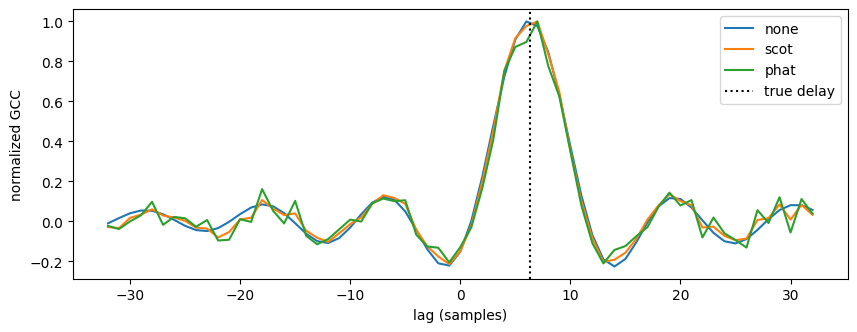

ITD  : 6.29 samples
GCC-none  : 6.30 samples
GCC-roth  : 6.30 samples
GCC-scot  : 6.29 samples
GCC-phat  : 6.20 samples
GCC-ht    : 6.31 samples


In [4]:
dark = lowpass(torch.randn(N), 1500)
dark = dark / dark.std() * 0.3
delayed = torch.stack([dark + 0.05 * torch.randn(N), fractional_delay(dark, 6.3) + 0.05 * torch.randn(N)])

fig, ax = plt.subplots(figsize=(10, 3.5))
for weighting in ["none", "scot", "phat"]:
    gcc = F.GeneralizedCrossCorrelation(weighting=weighting, frame_length=4096, n_fft=1024, max_delay=2e-3,
                                        mode="correlation", sr=SR)
    curve = gcc(delayed)[0].mean(-1)                     # (n_lags,) averaged over frames
    ax.plot(gcc.lags, curve / curve.max(), label=weighting)
ax.axvline(6.3, color="k", ls=":", label="true delay")
ax.set_xlabel("lag (samples)"); ax.set_ylabel("normalized GCC"); ax.legend(); plt.show()

print("ITD  : %.2f samples" % F.InterChannelTimeDifference(max_delay=2e-3, sr=SR)(delayed).mean())
for weighting in F.GeneralizedCrossCorrelation.weightings:
    gcc = F.GeneralizedCrossCorrelation(weighting=weighting, frame_length=4096, n_fft=1024, max_delay=2e-3, interp=8, sr=SR)
    print("GCC-%-5s : %.2f samples" % (weighting, gcc(delayed).mean()))

PHAT gives the sharpest peak, but weights all frequencies equally, including the bands above 1.5 kHz where only noise
remains : its estimate is slightly biased here. `"scot"` and `"ht"` weight frequencies by their coherence, and are
more robust to such noise. They use auto-spectra averaged over segments : they need several segments per frame
(`frame_length >> n_fft`, here 4096 and 1024). `interp` upsamples the correlation for sub-sample resolution.

### Tracking a moving source

Delays are given per frame : a source moving between two microphones gives a varying delay.

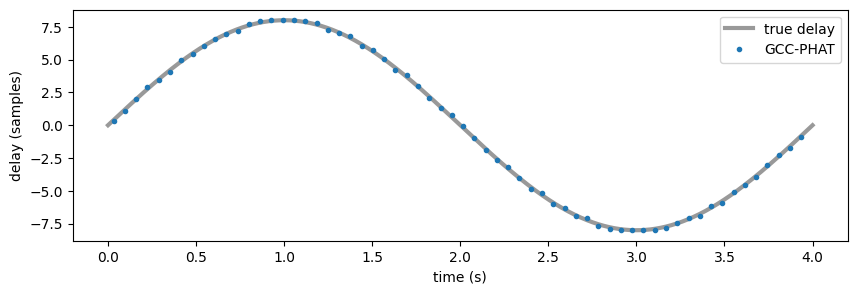

In [5]:
delay_curve = 8 * torch.sin(2 * math.pi * 0.25 * t)
# time-varying delay by linear interpolation
positions = torch.arange(N) - delay_curve
i0 = positions.floor().long().clamp(0, N - 2); frac = positions - positions.floor()
moving = torch.stack([source, (1 - frac) * source[i0] + frac * source[i0 + 1]])

gcc = F.GeneralizedCrossCorrelation(frame_length=1024, max_delay=1e-3, interp=4, sr=SR)
estimated = gcc(moving)[0]
frames = torch.arange(len(estimated)) * 1024 / SR + 512 / SR
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, delay_curve, "k", alpha=0.4, lw=3, label="true delay")
ax.plot(frames, estimated, ".", label="GCC-PHAT")
ax.set_xlabel("time (s)"); ax.set_ylabel("delay (samples)"); ax.legend(); plt.show()

### Direction of arrival with a microphone array

With `pairs="all"`, delays are given for every pair of microphones. For a linear array of 4 microphones (5 cm apart)
and a far-field source at azimuth θ, the delay of the pair (i, j) is `(x_j - x_i) sin θ / c` : θ is estimated by
least squares from all pairs.

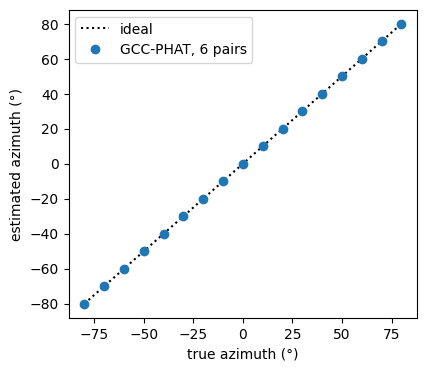

mean absolute error : 0.01°


In [6]:
c, spacing = 343., 0.05
mics = torch.arange(4) * spacing
gcc = F.GeneralizedCrossCorrelation(frame_length=2048, max_delay=None, interp=8, pairs="all", unit="seconds", sr=SR)
i, j = torch.triu_indices(4, 4, offset=1)
baselines = mics[j] - mics[i]

true_angles, estimated_angles = np.linspace(-80, 80, 17), []
for theta in true_angles:
    delays = mics * math.sin(math.radians(theta)) / c * SR
    array = torch.stack([fractional_delay(source, d) + 0.03 * torch.randn(N) for d in delays])
    tdoa = gcc(array).mean(-1)                                          # (6 pairs,) in seconds
    sin_theta = (baselines * tdoa).sum() / baselines.square().sum() * c
    estimated_angles.append(math.degrees(math.asin(sin_theta.clamp(-1, 1))))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(true_angles, true_angles, "k:", label="ideal")
ax.plot(true_angles, estimated_angles, "o", label="GCC-PHAT, 6 pairs")
ax.set_xlabel("true azimuth (°)"); ax.set_ylabel("estimated azimuth (°)"); ax.legend(); plt.show()
print("mean absolute error : %.2f°" % np.abs(np.array(estimated_angles) - true_angles).mean())

## Covariance and cross-spectral matrices

`SpatialCovariance` gives correlation matrices between channels per frame (or per frequency band with `n_bands`).
`CrossSpectralMatrix` gives cross-spectral matrices per frequency bin (Welch's method), as used in beamforming : its
`"coherence"` mode gives the magnitude squared coherence between channels per frequency.

Here, three microphones capture a low-passed source, plus independent noise : channels are coherent where the
source dominates (low frequencies), and incoherent above.

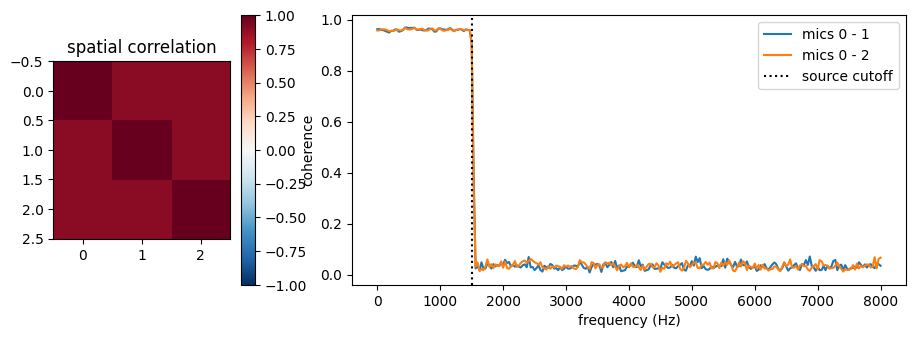

In [7]:
noisy_array = torch.stack([dark + 0.1 * torch.randn(N) for _ in range(3)])
cov = F.SpatialCovariance(sr=SR)(noisy_array).mean(-1)                   # (3, 3)
csm = F.CrossSpectralMatrix(n_fft=512, frame_length=8192, mode="coherence", sr=SR)
coherence = csm(noisy_array).mean(-1)                                      # (K, 3, 3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 2.5]})
im = axes[0].imshow(cov, vmin=-1, vmax=1, cmap="RdBu_r"); axes[0].set_title("spatial correlation"); plt.colorbar(im, ax=axes[0])
axes[1].plot(csm.frequencies, coherence[:, 0, 1], label="mics 0 - 1")
axes[1].plot(csm.frequencies, coherence[:, 0, 2], label="mics 0 - 2")
axes[1].axvline(1500, color="k", ls=":", label="source cutoff")
axes[1].set_xlabel("frequency (Hz)"); axes[1].set_ylabel("coherence"); axes[1].legend(); plt.show()

## Spectro-Spatial Covariance Vector (ambisonics)

`SpectroSpatialCovarianceVector` (SSCV, Meng et al., ICASSP 2025) summarizes covariance matrices of first-order
ambisonics (FOA) recordings in mel bands : `M^2 = 16` values per band, the log energy followed by gain-invariant
values. We encode a plane wave in FOA (W, Y, Z, X, ACN ordering) at several azimuths : some components of the SSCV
follow the direction of the source.

SSCV shape for 1 s of FOA : (16, 52, 19) (16 values, n_bands, n_frames)


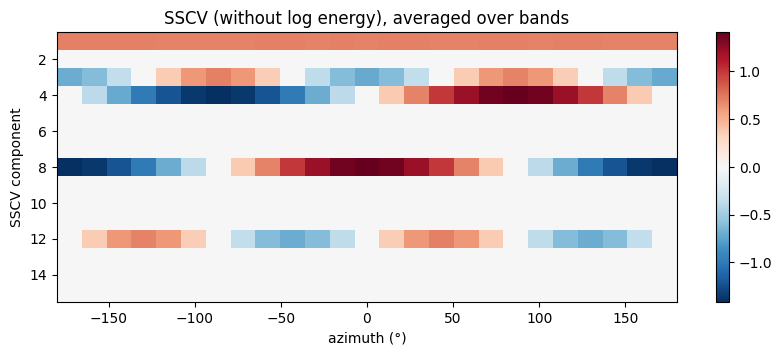

In [8]:
def foa(signal, azimuth, elevation=0.):
    az, el = math.radians(azimuth), math.radians(elevation)
    return torch.stack([signal, signal * math.sin(az) * math.cos(el), signal * math.sin(el), signal * math.cos(az) * math.cos(el)])

sscv = F.SpectroSpatialCovarianceVector(sr=SR)
azimuths = np.arange(-180, 181, 15)
vectors = torch.stack([sscv(foa(source[:SR], az) + 0.01 * torch.randn(4, SR)).mean((-1, -2)) for az in azimuths])   # (n_azimuths, 16)
print("SSCV shape for 1 s of FOA :", tuple(sscv(foa(source[:SR], 0.)).shape), "(16 values, n_bands, n_frames)")

fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(vectors[:, 1:].T, aspect="auto", cmap="RdBu_r", extent=(azimuths[0], azimuths[-1], 15.5, 0.5))
ax.set_xlabel("azimuth (°)"); ax.set_ylabel("SSCV component"); ax.set_title("SSCV (without log energy), averaged over bands")
plt.colorbar(im); plt.show()